In [168]:
import numpy as np
import cv2
from google.colab.patches import cv2_imshow
import matplotlib.pyplot as plt

In [169]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


(360, 640, 3) True 29.97002997002997


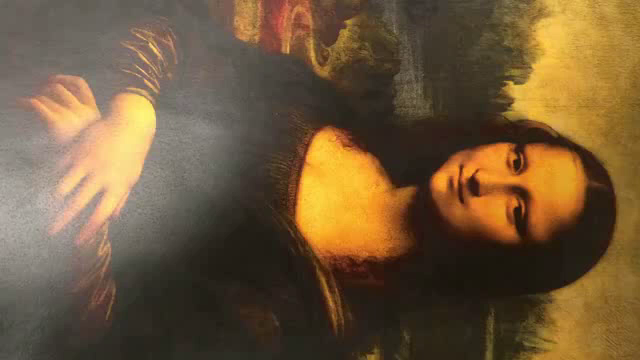

In [170]:
input_video_path = '/content/drive/MyDrive/cv_videos/mona-lisa.mp4'

cap = cv2.VideoCapture(input_video_path)

if(cap.isOpened()):
  ret, frame = cap.read()
  fps = cap.get(cv2.CAP_PROP_FPS)
  print(frame.shape, ret, fps)
  if ret:
    cv2_imshow(frame)

cap.release()

Следующий шаг: ключевые точки на шаблоне. Использую Scale Invariant Feature Transform (SIFT) algorithm

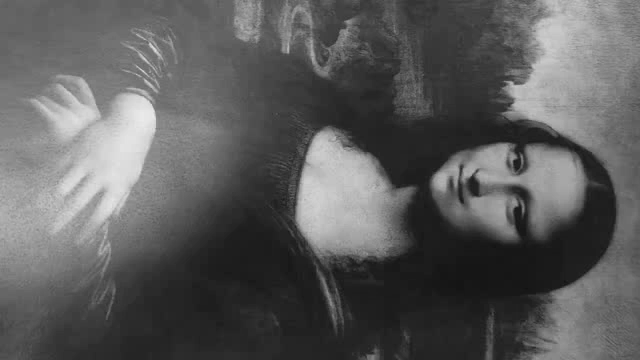

In [171]:
img1 = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

cv2_imshow(img1)

In [172]:
sift = cv2.SIFT_create()

kp1, desc1 = sift.detectAndCompute(img1, None)

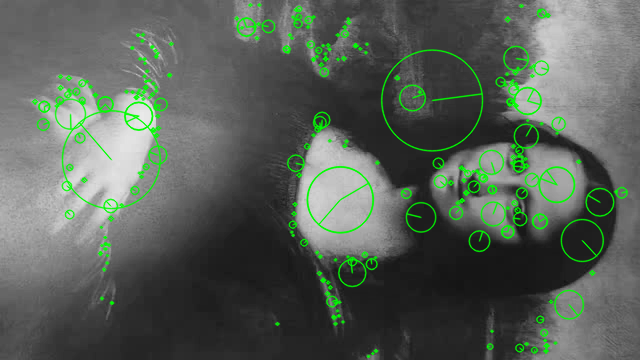

In [173]:
output_img1 = cv2.drawKeypoints(img1, kp1, None, (0, 255, 0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

cv2_imshow(output_img1)

In [174]:
print(len(kp1), desc1.shape)

316 (316, 128)


Посмотрим на объект с другой стороны и попробуем выделить точки - посмотрим на кадр 151

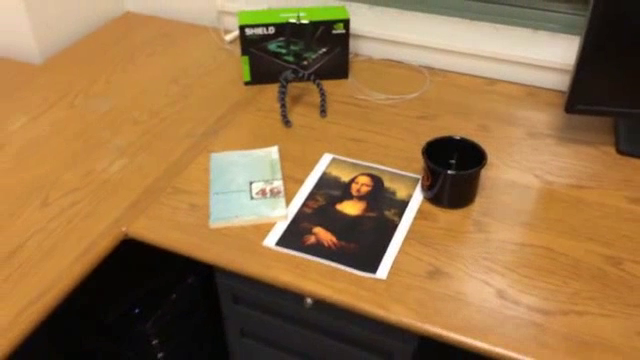

In [175]:
cap = cv2.VideoCapture(input_video_path)
cap.set(cv2.CAP_PROP_POS_FRAMES, 150)

ret, frame = cap.read()
img2 = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

cv2_imshow(frame)

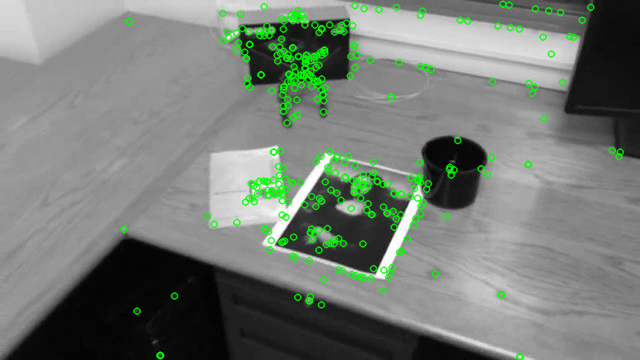

In [176]:
kp2, desc2 = sift.detectAndCompute(img2, None)
output_image150 = cv2.drawKeypoints(img2, kp2, None, (0, 255, 0), flags=cv2.DRAW_MATCHES_FLAGS_NOT_DRAW_SINGLE_POINTS)

cv2_imshow(output_image150)

Сопоставим:

In [177]:
bf = cv2.BFMatcher()
matches = bf.knnMatch(desc1, desc2, k=2)
len(matches)

316

In [178]:
matched = cv2.drawMatchesKnn(img1, kp1, img2, kp2, matches, None)
cv2.imwrite('Match.jpg', matched)

True

In [179]:
good_pairs = []

for (m,n) in matches:
  if(m.distance < 0.75 * n.distance):
    good_pairs.append(m)

good_matched = cv2.drawMatches(img1, kp1, img2, kp2, good_pairs, None)
cv2.imwrite('Match_good.jpg', good_matched)

len(good_pairs)

12

12 пар — это немного, но объяснимо:

- на 150-м кадре картина маленькая: она примерно в 4–5 раз меньше, чем на шаблоне. Мелкие детали, на которых шаблон нашёл много точек (складки, пальцы), на кадре слились в несколько пикселей;

- картина видна под углом, и дескрипторы из-за этого искажаются.


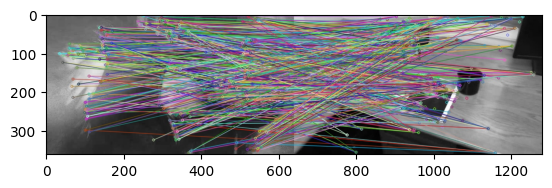

In [180]:
img_without_filter = plt.imread('/content/Match.jpg')
img_with_filter = plt.imread('/content/Match_good.jpg')

plt.imshow(img_without_filter)

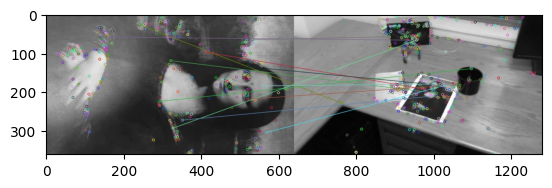

In [181]:
plt.imshow(img_with_filter)

Следующий шаг - гомография

[[ 2.12968711e-01  2.23138092e-01  2.75980014e+02]
 [-7.84159391e-02  5.85727423e-02  2.47441372e+02]
 [ 3.55594834e-04 -2.17953648e-06  1.00000000e+00]]
6


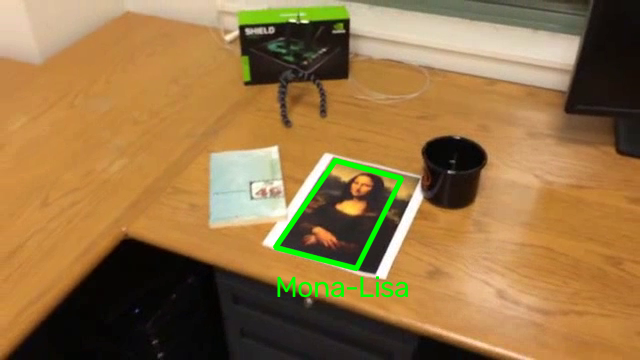

In [191]:
MIN_MATCH_COUNT = 10
MIN_INLIERS = 6
MIN_AREA = 500   # площадь в пикселях

if len(good_pairs) > MIN_MATCH_COUNT:
  src_pts = np.float32([kp1[m.queryIdx].pt for m in good_pairs]).reshape(-1, 1, 2)
  dst_pts = np.float32([kp2[m.trainIdx].pt for m in good_pairs]).reshape(-1, 1, 2)

  H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
  matchesMask = mask.ravel().tolist()

  print(H)
  print(mask.sum())

  h, w = img1.shape
  pts = np.float32( [[0,0], [0, h-1], [w-1, h-1], [w-1, 0]] ).reshape(-1, 1, 2)
  dst = cv2.perspectiveTransform(pts, H)

  frame = cv2.polylines(frame, [np.int32(dst)], True, (0, 255, 0), 3, cv2.LINE_AA)
  frame = cv2.putText(frame, "Mona-Lisa", (int(dst[0][0][0]), int(dst[0][0][1])+50), cv2.FONT_HERSHEY_COMPLEX, 1, (0, 255, 0), 1)

  cv2_imshow(frame)

else:
  print("Недостаточно совпадений")
  matchesMask = None

Поместим теперь это в функцию

In [192]:
def getAngles(img, kp1, desc1, pts, sift, bf):
  # точки и дескрипторы кадра
  kp2, desc2 = sift.detectAndCompute(img, None)
  if (desc2 is None) or (len(kp2) < 2):
    return None, 0

  # сопоставление
  matches = bf.knnMatch(desc1, desc2, k=2)

  good_pairs = []

  # ratio тест
  for (m,n) in matches:
    if(m.distance < 0.75 * n.distance):
      good_pairs.append(m)

  if len(good_pairs) > MIN_MATCH_COUNT:
    src_pts = np.float32([kp1[m.queryIdx].pt for m in good_pairs]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp2[m.trainIdx].pt for m in good_pairs]).reshape(-1, 1, 2)

  # гомография
    H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
    if (H is None) or (mask.sum() < MIN_INLIERS):
      return None, 0

    dst = cv2.perspectiveTransform(pts, H)

    # проверка формы: рамка должна быть выпуклым четырёхугольником разумного размера
    quad = np.int32(dst)
    if not cv2.isContourConvex(quad):
      return None, 0
    if cv2.contourArea(quad) < MIN_AREA:
      return None, 0

  else:
    return None, 0

  return dst, int(mask.sum())


In [210]:
import time

In [211]:
def full_work(inputPath, outputPath, title):
  cap = cv2.VideoCapture(inputPath)

  if(cap.isOpened()):
    ret, frame = cap.read()

  # sift = cv2.SIFT_create()
  sift = cv2.SIFT_create(contrastThreshold=0.02)   # по умолчанию 0.04
  bf = cv2.BFMatcher()
  img1 = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
  kp1, desc1 = sift.detectAndCompute(img1, None)

  h, w = img1.shape
  pts = np.float32( [[0,0], [0, h-1], [w-1, h-1], [w-1, 0]] ).reshape(-1, 1, 2)

  fps = cap.get(cv2.CAP_PROP_FPS)

  writer = cv2.VideoWriter(outputPath, cv2.VideoWriter_fourcc(*'mp4v'), fps, (w, h))

  count = 0
  stats = []

  t0 = time.time()
  while True:
    ret, frame = cap.read()
    if not ret:
      break

    img = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    dst, inliers = getAngles(img, kp1, desc1, pts, sift, bf)

    stats.append(inliers)

    if dst is not None:
      frame = cv2.polylines(frame, [np.int32(dst)], True, (0, 255, 0), 3, cv2.LINE_AA)
      frame = cv2.putText(frame, title, (int(dst[0][0][0]), int(dst[0][0][1])-30), cv2.FONT_HERSHEY_COMPLEX, 1, (0, 255, 0), 1)

    writer.write(frame)
    count+=1

    if count % 50 == 0:
      print(f'кадр {count}, прошло {time.time() - t0:.0f} с')

  cap.release()
  writer.release()

  return stats

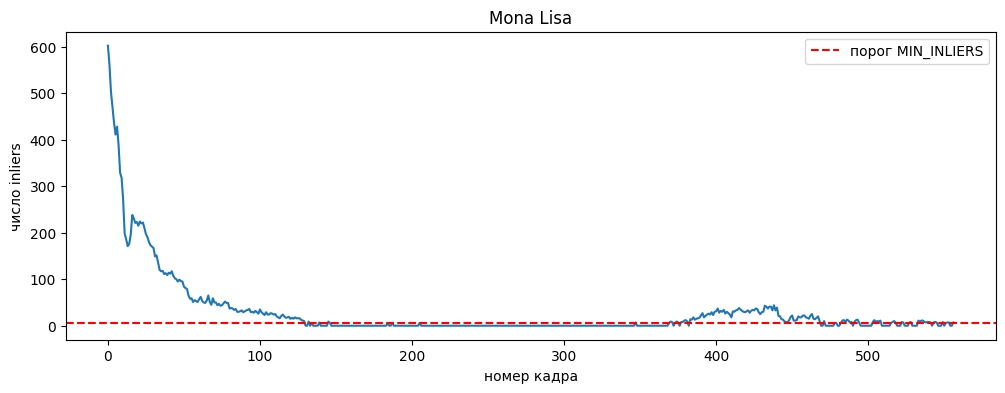

Объект найден на 282 из 557 кадров (50.6%)


In [196]:
import matplotlib.pyplot as plt

stats = full_work("/content/drive/MyDrive/cv_videos/mona-lisa.mp4", "/content/mona-lisa-out.mp4", "Mona-Lisa")

plt.figure(figsize=(12, 4))
plt.plot(stats)
plt.axhline(MIN_INLIERS, color='red', linestyle='--', label='порог MIN_INLIERS')
plt.xlabel('номер кадра')
plt.ylabel('число inliers')
plt.title('Mona Lisa')
plt.legend()
plt.show()

found = sum(1 for s in stats if s > 0)
print(f'Объект найден на {found} из {len(stats)} кадров ({100 * found / len(stats):.1f}%)')

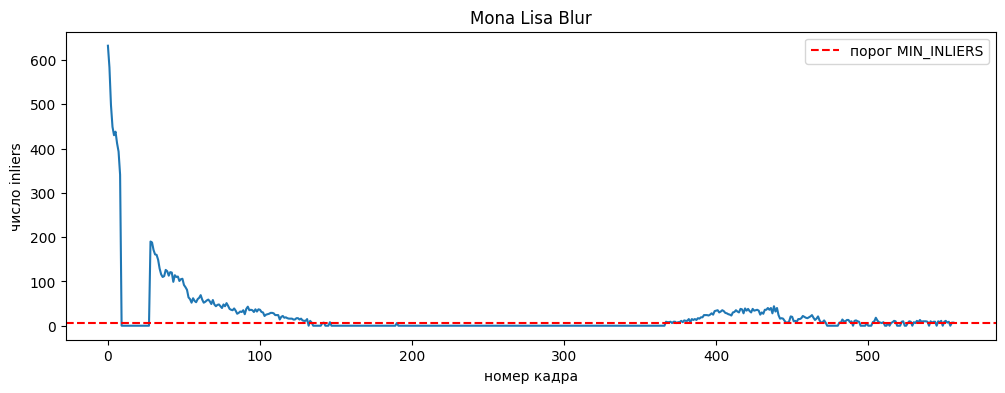

Объект найден на 280 из 557 кадров (50.3%)


In [197]:
stats = full_work("/content/drive/MyDrive/cv_videos/mona-lisa-blur.mp4", "/content/mona-lisa-blur-out.mp4", "Mona-Lisa")

plt.figure(figsize=(12, 4))
plt.plot(stats)
plt.axhline(MIN_INLIERS, color='red', linestyle='--', label='порог MIN_INLIERS')
plt.xlabel('номер кадра')
plt.ylabel('число inliers')
plt.title('Mona Lisa Blur')
plt.legend()
plt.show()

found = sum(1 for s in stats if s > 0)
print(f'Объект найден на {found} из {len(stats)} кадров ({100 * found / len(stats):.1f}%)')

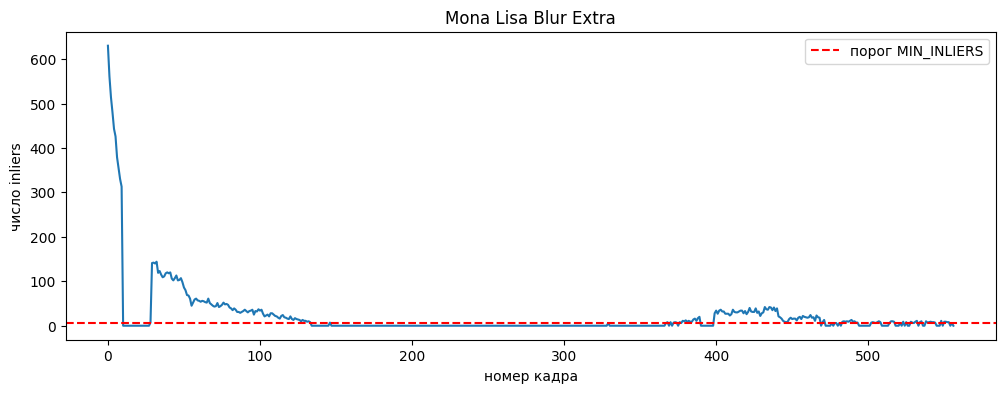

Объект найден на 259 из 557 кадров (46.5%)


In [198]:
stats = full_work("/content/drive/MyDrive/cv_videos/mona-lisa-blur-extra-credit.mp4", "/content/mona-lisa-blur-extra-out.mp4", "Mona-Lisa")

plt.figure(figsize=(12, 4))
plt.plot(stats)
plt.axhline(MIN_INLIERS, color='red', linestyle='--', label='порог MIN_INLIERS')
plt.xlabel('номер кадра')
plt.ylabel('число inliers')
plt.title('Mona Lisa Blur Extra')
plt.legend()
plt.show()

found = sum(1 for s in stats if s > 0)
print(f'Объект найден на {found} из {len(stats)} кадров ({100 * found / len(stats):.1f}%)')

In [208]:
!ffmpeg -i /content/drive/MyDrive/cv_videos/myVideo.mp4 -vf scale=480:-2 -an /content/my_video_small.mp4

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

кадр 50, прошло 34 с
кадр 100, прошло 68 с
кадр 150, прошло 125 с
кадр 200, прошло 191 с
кадр 250, прошло 267 с
кадр 300, прошло 342 с
кадр 350, прошло 404 с
кадр 400, прошло 464 с
кадр 450, прошло 531 с
кадр 500, прошло 597 с
кадр 550, прошло 670 с
кадр 600, прошло 743 с
кадр 650, прошло 814 с
кадр 700, прошло 886 с


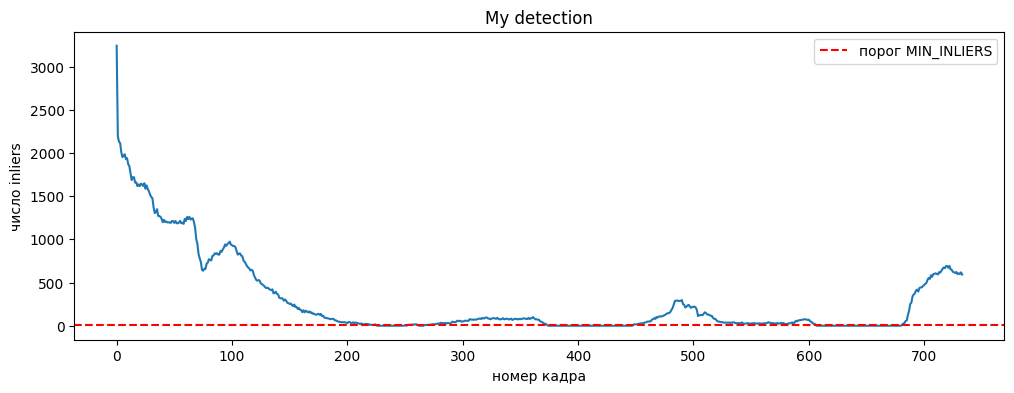

Объект найден на 556 из 734 кадров (75.7%)


In [214]:
stats = full_work("/content/my_video_small.mp4", "/content/my_detection.mp4", "Card")

plt.figure(figsize=(12, 4))
plt.plot(stats)
plt.axhline(MIN_INLIERS, color='red', linestyle='--', label='порог MIN_INLIERS')
plt.xlabel('номер кадра')
plt.ylabel('число inliers')
plt.title('My detection')
plt.legend()
plt.show()

found = sum(1 for s in stats if s > 0)
print(f'Объект найден на {found} из {len(stats)} кадров ({100 * found / len(stats):.1f}%)')